# SAMI · Notebook 6 — Can the chosen model be improved?

**Mandate.** Notebook 5 ended with a choice: **Corrected + synthetic** (4,191 + 26,057 = 30,248 messages, synthetic at
full weight) with an **RBF SVM, C=10**: accuracy 83.2%, macro-F1 0.769 against the final labels. This notebook varies
the parameters around it, with a small search fixed in advance, to see whether a clearly better setting exists.
Modules compute (`sami.categorize`), this notebook consumes.

> **Rules.**
>
> 1. **Same frozen test as notebook 5** (588 messages, 566 with a final label), so the numbers are comparable.
>    Metric: macro-F1 against the final labels, accuracy beside it.
> 2. **The test is also where the variants are compared**, so the best variant's score is somewhat optimistic
>    (selected on the test). The grid is fixed before any run and is small (about 25 fits, plus 3 at the grid edge), and a change is adopted
>    only under the rule below.
> 3. **Adoption rule.** A variant replaces the current setting only if its macro-F1 beats the current by **at least
>    0.01** *and* its neighbours in the same parameter (one step either side in the order shown) are not worse than the
>    current. Otherwise the current setting stays: it is on a plateau. 0.01 is a floor, not a significance test.
> 4. **The baseline must reproduce notebook 5** (accuracy 83.2%, macro-F1 0.769): asserted.
> 5. **No test text in any training set** (asserted). **No message text is printed or saved**; outputs are counts,
>    scores and charts.

In [1]:
import sys, pathlib
# Locate src/ by walking up from the working directory, so `sami` imports whether the kernel starts in
# notebooks/ (JupyterLab) or at the repo root (VS Code).
_cwd = pathlib.Path.cwd()
_src = next((p / "src" for p in (_cwd, *_cwd.parents) if (p / "src" / "sami").is_dir()), None)
if _src is None:
    raise RuntimeError(f"Could not find src/sami/ above {_cwd}. Run this notebook from inside the repository.")
sys.path.insert(0, str(_src))
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report
from sami import categorize as cz, nlp, theme

ROOT = _src.parent
LABELS = ROOT / "datasets" / "labels"
CACHE = ROOT / "notebooks" / "cache" / "category_embeddings.npz"            # shared with notebook 4
CACHE_SYN = ROOT / "notebooks" / "cache" / "synthetic_embeddings.npz"
MEMO = LABELS / "llm_haiku_synth" / "embeddings.pkl"                        # vectors computed while deduplicating
SRC = "source: MMC client labels + Claude Haiku labels and synthetic messages"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

dev_info = nlp.device_report()
print(f"Compute    : {dev_info['device']} ({dev_info['gpu']}) · torch {dev_info['torch']}")
print(f"Embeddings : {dev_info['embed_model']} @ {dev_info['embed_revision'][:12]}")

Compute    : cpu (None) · torch 2.13.0+cpu
Embeddings : intfloat/multilingual-e5-large @ 3d7cfbdacd47


## 1 · The data and the baseline

Exactly notebook 5's training data: the Corrected sample (final labels without the test set and without the
unreviewed disagreements, each distinct text once) plus all 26,057 synthetic messages labelled with
`Categoría objetivo`. `flagged` marks the 1,258 synthetic rows that Haiku's check disagreed with (used by one
variant only).

In [2]:
df = cz.load_labeled()
X_all = cz.cached_embeddings(df["text"].tolist(), CACHE)
is_test = cz.frozen_split(df)
lab = df["label"].notna().to_numpy()
y = df["label"].to_numpy()
groups = pd.factorize(cz._norm(df["text"]))[0]
dev_idx = np.flatnonzero(lab & ~is_test.to_numpy())
test_idx = np.flatnonzero(lab & is_test.to_numpy())
assert len(test_idx) == 588 and (y[test_idx] != cz.NONE).sum() == 501, "frozen test set changed"
assert not set(groups[dev_idx]) & set(groups[test_idx]), "a message text sits on both sides of the split"

syn = cz.load_synthetic(all_rows=True)
X_syn = cz.embeddings_with_memo(syn["text"].tolist(), CACHE_SYN, MEMO)
y_syn = syn["label"].to_numpy()
assert len(syn) == 26_057, "the synthetic set changed"
test_texts = set(cz._norm(df["text"].iloc[test_idx]))
assert not test_texts & set(cz._norm(syn["text"])), "a synthetic text equals a frozen-test text"
flagged = ~syn["text"].isin(set(cz.load_synthetic()["text"])).to_numpy()          # Haiku's check disagreed
assert flagged.sum() == 1_258, "the flagged synthetic rows changed"

final = pd.read_excel(LABELS / "messages_category_haiku_final.xlsx", usecols=["id", "Etiqueta final", "Fuente final", "split"])
assert (df["row"].to_numpy() == np.arange(len(df))).all()
y_final = df["row"].map(final.set_index("id")["Etiqueta final"]).to_numpy()
has_final = pd.notna(y_final[test_idx])
yf_test = y_final[test_idx][has_final]

cand = final[(final["split"] != "prueba") & (final["Fuente final"] != "LLM, discrepa (sin revisar)")]
norm_d = cz._norm(df["text"].iloc[cand["id"].to_numpy()])
cand = cand[~norm_d.isin(test_texts).to_numpy()]
cand = cand[~cz._norm(df["text"].iloc[cand["id"].to_numpy()]).duplicated().to_numpy()]
rows_d = cand["id"].to_numpy()
X_d, y_d = X_all[rows_d], cand["Etiqueta final"].to_numpy()
assert len(rows_d) == 4_191, "the Corrected sample changed"
assert not test_texts & set(cz._norm(df["text"].iloc[rows_d])), "a Corrected text equals a frozen-test text"

X_tr = np.vstack([X_d, X_syn]); y_tr = np.r_[y_d, y_syn]
is_syn = np.r_[np.zeros(len(y_d), bool), np.ones(len(y_syn), bool)]
flag_tr = np.r_[np.zeros(len(y_d), bool), flagged]
assert len(y_tr) == 30_248
Xt = X_all[test_idx]
CL = list(cz.CLASSES)
GAMMA0 = 1.0 / (X_tr.shape[1] * X_tr.var())                       # sklearn's gamma="scale" on the full training set
print(f"Training rows {len(y_tr):,} = {len(y_d):,} corrected + {len(y_syn):,} synthetic ({int(flagged.sum()):,} flagged) · "
      f"test {len(test_idx)} ({int(has_final.sum())} with a final label) · default gamma {GAMMA0:.3f}")

Training rows 30,248 = 4,191 corrected + 26,057 synthetic (1,258 flagged) · test 588 (566 with a final label) · default gamma 1.001


In [3]:
RESULTS, PREDS, DEC = [], {}, {}                                  # one row / prediction / test scores per fit

def evaluate(step, variant, p, Xa_n, fit_s, C_=None, gmult=None):
    f = cz.scores(yf_test, p[has_final], CL)
    RESULTS.append({"Step": step, "Variant": variant, "C": C_, "gamma ×": gmult, "Size": Xa_n,
                    "Fit (s)": fit_s, "Acc (final labels)": f["accuracy"], "Final labels": f["macro_f1"]})
    PREDS[variant] = p

def fit_eval(step, variant, Xa, ya, C_=10, gmult=1.0, class_weight="balanced", sample_weight=None, Xtest=None):
    """One RBF SVM fit scored once on the frozen test; stores the predictions and the test scores."""
    gamma = gmult / (Xa.shape[1] * Xa.var())                       # gmult=1 is gamma="scale"
    t0 = time.perf_counter()
    m = SVC(C=C_, gamma=gamma, class_weight=class_weight, cache_size=1000).fit(Xa, ya, sample_weight=sample_weight)
    sec = time.perf_counter() - t0
    Xe = Xt if Xtest is None else Xtest
    DEC[variant] = (m.classes_, m.decision_function(Xe))
    evaluate(step, variant, m.predict(Xe), len(ya), sec, C_, gmult)

fit_eval("1 · grid", "C=10, gamma ×1  (baseline)", X_tr, y_tr, 10, 1.0)
base = RESULTS[0]
assert round(base["Acc (final labels)"], 3) == 0.832 and round(base["Final labels"], 3) == 0.769, "baseline no longer matches notebook 5"
print(f"Baseline reproduces notebook 5: accuracy {base['Acc (final labels)']:.1%}, macro-F1 {base['Final labels']:.3f} ({base['Fit (s)']:.0f}s)")

Baseline reproduces notebook 5: accuracy 83.2%, macro-F1 0.769 (100s)


## 2 · C × gamma

C in {3, 10, 30, 100} × gamma at 0.5×, 1× and 2× the default (`scale`). Twelve fits, the baseline being one of them.
Each is fitted once and scored once.

In [4]:
CS, GMS = [3, 10, 30, 100], [0.5, 1.0, 2.0]
for C_ in CS:
    for gm in GMS:
        if (C_, gm) != (10, 1.0):
            fit_eval("1 · grid", f"C={C_}, gamma ×{gm:g}", X_tr, y_tr, C_, gm)
res = pd.DataFrame(RESULTS)
grid = res[res["Step"] == "1 · grid"]
f1g = grid.pivot(index="C", columns="gamma ×", values="Final labels").loc[CS, GMS]
acg = grid.pivot(index="C", columns="gamma ×", values="Acc (final labels)").loc[CS, GMS]
print(f"gamma = {' · '.join(f'{gm:g}× = {gm * GAMMA0:.3f}' for gm in GMS)}")
print(f"Grid fit time: {grid['Fit (s)'].sum():.0f}s in total, longest {grid['Fit (s)'].max():.0f}s")
f1g.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None)

gamma = 0.5× = 0.500 · 1× = 1.001 · 2× = 2.001
Grid fit time: 1430s in total, longest 158s


gamma ×,0.500000,1.000000,2.000000
C,,,
3,0.753,0.767,0.772
10,0.764,0.769,0.751
30,0.750,0.756,0.746
100,0.745,0.745,0.748


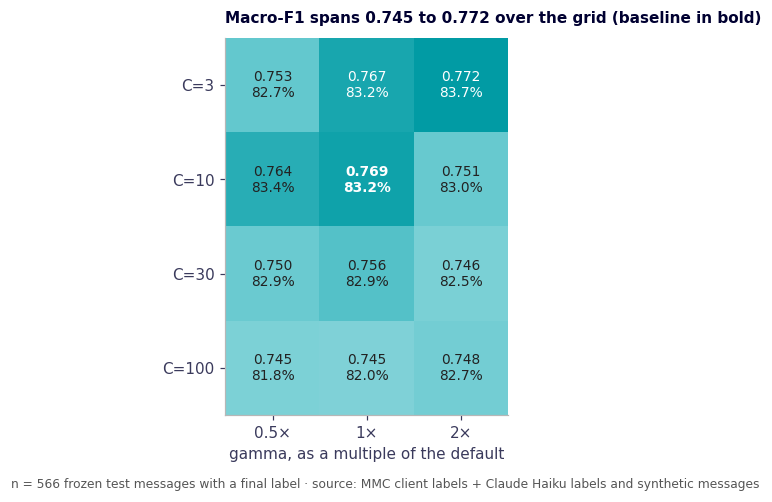

In [5]:
# --- Figure 1: macro-F1 (cell colour) and accuracy (second line) over the C x gamma grid ---
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.imshow(f1g.to_numpy(), cmap=theme.blue_cmap(), vmin=f1g.to_numpy().min() - 0.05, vmax=f1g.to_numpy().max() + 0.02)
for i, C_ in enumerate(CS):
    for j, gm in enumerate(GMS):
        ax.text(j, i, f"{f1g.loc[C_, gm]:.3f}" + chr(10) + f"{acg.loc[C_, gm]:.1%}", ha="center", va="center", fontsize=9,
                color="white" if f1g.loc[C_, gm] > f1g.to_numpy().mean() + 0.01 else "#222",
                fontweight="bold" if (C_, gm) == (10, 1.0) else None)
ax.set_xticks(range(len(GMS)), [f"{gm:g}×" for gm in GMS]); ax.set_yticks(range(len(CS)), [f"C={c}" for c in CS])
ax.set_xlabel("gamma, as a multiple of the default"); ax.set_ylabel("")
ax.set_title(f"Macro-F1 spans {f1g.to_numpy().min():.3f} to {f1g.to_numpy().max():.3f} over the grid (baseline in bold)", loc="left", fontsize=10)
fig.text(0.01, -0.02, f"n = {int(has_final.sum())} frozen test messages with a final label · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

In [6]:
BASE_F1 = base["Final labels"]
def adopted(ordered, scores, baseline_key, floor=0.01):
    """The adoption rule: best value beats the baseline by `floor` and its neighbours in `ordered` are not worse."""
    best = max(ordered, key=lambda k: scores[k])
    if best == baseline_key or scores[best] - scores[baseline_key] < floor:
        return None
    i = ordered.index(best)
    nb = [ordered[j] for j in (i - 1, i + 1) if 0 <= j < len(ordered)]
    return best if all(scores[n] >= scores[baseline_key] for n in nb) else None

# Step 1 adoption, along both axes: the best cell must clear the floor and have both axis-neighbours not below the baseline.
cells = {(c, g): f1g.loc[c, g] for c in CS for g in GMS}
best_cell = max(cells, key=cells.get)
nbrs = [(CS[CS.index(best_cell[0]) + d], best_cell[1]) for d in (-1, 1) if 0 <= CS.index(best_cell[0]) + d < len(CS)] + \
       [(best_cell[0], GMS[GMS.index(best_cell[1]) + d]) for d in (-1, 1) if 0 <= GMS.index(best_cell[1]) + d < len(GMS)]
if best_cell != (10, 1.0) and cells[best_cell] - BASE_F1 >= 0.01 and all(cells[n] >= BASE_F1 for n in nbrs):
    CENTRE = best_cell
    print(f"Step 1 adopts C={CENTRE[0]}, gamma ×{CENTRE[1]:g} (macro-F1 {cells[CENTRE]:.3f} against {BASE_F1:.3f}).")
else:
    CENTRE = (10, 1.0)
    print(f"Step 1 adopts nothing: best cell C={best_cell[0]}, gamma ×{best_cell[1]:g} is {cells[best_cell]:.3f} against {BASE_F1:.3f}"
          f" (gain {cells[best_cell] - BASE_F1:+.3f}); the baseline stays.")
C0, GM0 = CENTRE
CENTRE_NAME = f"C={C0}, gamma ×{GM0:g}" + ("  (baseline)" if CENTRE == (10, 1.0) else "")
print("Centre for step 2:", CENTRE_NAME)

Step 1 adopts nothing: best cell C=3, gamma ×2 is 0.772 against 0.769 (gain +0.003); the baseline stays.
Centre for step 2: C=10, gamma ×1  (baseline)


## 3 · One change at a time, around the centre

Each variant changes one thing from the centre of step 1 (the baseline unless step 1 adopted a cell). The order in
which values are listed is the order used by the adoption rule's "neighbours". The Ninguna bias reuses the
centre's fitted scores (no extra fit): a constant added to the *Ninguna* column before the argmax.

In [7]:
CENTRE_KEY = "C=10, gamma ×1  (baseline)" if CENTRE == (10, 1.0) else f"C={C0}, gamma ×{GM0:g}"
rng = np.random.default_rng(0)
syn_pos = np.flatnonzero(is_syn)
N_CORR = {c: int((y_d == c).sum()) for c in CL}
def step2(variant, Xa, ya, **kw):
    fit_eval("2 · one change", variant, Xa, ya, C0, GM0, **kw)

# synthetic weight
for w in (0.5, 0.25, 0.1):
    step2(f"synthetic weight {w:g}", X_tr, y_tr, sample_weight=np.where(is_syn, w, 1.0))
# synthetic cap per class: at most k x the Corrected count of that class
for k in (1, 2):
    keep = np.flatnonzero(~is_syn)
    for c in CL:
        pool = syn_pos[y_tr[syn_pos] == c]
        keep = np.r_[keep, rng.permutation(pool)[: k * N_CORR[c]]]
    keep = np.sort(keep)
    step2(f"synthetic cap {k}× corrected", X_tr[keep], y_tr[keep])
# class weights: none, square root of balanced
step2("class weights: none", X_tr, y_tr, class_weight=None)
cnt = pd.Series(y_tr).value_counts()
sqrt_bal = {c: float(np.sqrt(len(y_tr) / (len(cnt) * cnt[c]))) for c in cnt.index}
step2("class weights: sqrt(balanced)", X_tr, y_tr, class_weight=sqrt_bal)
# drop the synthetic rows Haiku's check disagreed with
step2("drop flagged synthetic (1,258)", X_tr[~flag_tr], y_tr[~flag_tr])
# PCA: fitted on the training rows only
for nd in (256, 512):
    pca = PCA(nd, random_state=0).fit(X_tr)
    step2(f"PCA {nd} dims", pca.transform(X_tr), y_tr, Xtest=pca.transform(Xt))
# Ninguna bias on the centre's scores (no new fit)
cls, dec = DEC[CENTRE_KEY]
ni = list(cls).index(cz.NONE)
for delta in (-0.2, 0.2):
    d2 = dec.copy(); d2[:, ni] += delta
    evaluate("2 · one change", f"Ninguna bias {delta:+.1f}", cls[d2.argmax(axis=1)], len(y_tr), 0.0, C0, GM0)

res = pd.DataFrame(RESULTS)
cen = res.loc[res["Variant"] == CENTRE_KEY].iloc[0]
res["Δ macro-F1 vs centre"] = res["Final labels"] - cen["Final labels"]
res["Δ acc vs centre"] = res["Acc (final labels)"] - cen["Acc (final labels)"]
show = res[res["Step"] == "2 · one change"].drop(columns=["Step", "C", "gamma ×"])
print(f"Centre: {CENTRE_KEY}: accuracy {cen['Acc (final labels)']:.1%}, macro-F1 {cen['Final labels']:.3f}. Step 2 fit time {show['Fit (s)'].sum():.0f}s.")
show.style.hide(axis="index").format({"Size": "{:,}", "Fit (s)": "{:.0f}", "Acc (final labels)": "{:.1%}", "Final labels": "{:.3f}",
                                      "Δ macro-F1 vs centre": "{:+.3f}", "Δ acc vs centre": "{:+.1%}"})

Centre: C=10, gamma ×1  (baseline): accuracy 83.2%, macro-F1 0.769. Step 2 fit time 930s.


Variant,Size,Fit (s),Acc (final labels),Final labels,Δ macro-F1 vs centre,Δ acc vs centre
synthetic weight 0.5,"30,248",127,83.7%,0.772,+0.003,+0.5%
synthetic weight 0.25,"30,248",141,83.4%,0.768,-0.001,+0.2%
synthetic weight 0.1,"30,248",182,83.4%,0.779,+0.010,+0.2%
synthetic cap 1× corrected,"8,382",20,81.6%,0.731,-0.038,-1.6%
synthetic cap 2× corrected,"12,573",34,82.3%,0.749,-0.020,-0.9%
class weights: none,"30,248",89,83.6%,0.769,-0.001,+0.4%
class weights: sqrt(balanced),"30,248",90,83.4%,0.754,-0.015,+0.2%
"drop flagged synthetic (1,258)","28,990",83,83.2%,0.770,+0.001,+0.0%
PCA 256 dims,"30,248",41,82.7%,0.753,-0.016,-0.5%
PCA 512 dims,"30,248",123,82.7%,0.746,-0.023,-0.5%


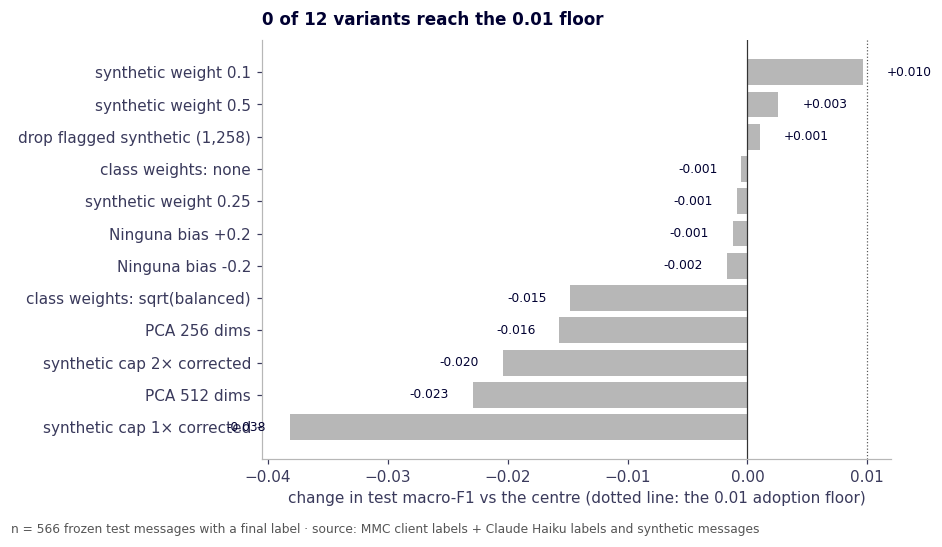

In [8]:
# --- Figure 2: change in macro-F1 against the centre, every variant of step 2 ---
d = res[res["Step"] == "2 · one change"].sort_values("Δ macro-F1 vs centre")
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.barh(d["Variant"], d["Δ macro-F1 vs centre"], color=[theme.TEAL if v >= 0.01 else theme.GREY for v in d["Δ macro-F1 vs centre"]])
for i, v in enumerate(d["Δ macro-F1 vs centre"]):
    ax.text(v + (0.002 if v >= 0 else -0.002), i, f"{v:+.3f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="#333", lw=0.8); ax.axvline(0.01, color="#555", lw=0.8, ls=":")
ax.set_xlabel("change in test macro-F1 vs the centre (dotted line: the 0.01 adoption floor)")
ax.set_title(f"{int((d['Δ macro-F1 vs centre'] >= 0.01).sum())} of {len(d)} variants reach the 0.01 floor", loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {int(has_final.sum())} frozen test messages with a final label · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

In [9]:
# Adoption rule, group by group (neighbours in the order listed; the centre is the neutral element).
F = res.set_index("Variant")["Final labels"].to_dict()
F["centre"] = F[CENTRE_KEY]
groups_ = {
    "synthetic weight":  (["centre", "synthetic weight 0.5", "synthetic weight 0.25", "synthetic weight 0.1"]),
    "synthetic cap":     (["synthetic cap 1× corrected", "synthetic cap 2× corrected", "centre"]),
    "class weights":     (["class weights: none", "class weights: sqrt(balanced)", "centre"]),
    "Ninguna bias":      (["Ninguna bias -0.2", "centre", "Ninguna bias +0.2"]),
    "flagged synthetic": (["drop flagged synthetic (1,258)", "centre"]),
    "dimensions":        (["PCA 256 dims", "PCA 512 dims", "centre"]),
}
ADOPTED = {}
for g, order in groups_.items():
    pick = adopted(order, F, "centre")
    ADOPTED[g] = pick
    best = max(order, key=lambda k: F[k])
    print(f"{g:18s} best {best if best != 'centre' else 'the centre':34s} {F[best] - F['centre']:+.3f}  ->  " + (f"ADOPT {pick}" if pick else "keep the centre"))

synthetic weight   best synthetic weight 0.1               +0.010  ->  keep the centre
synthetic cap      best the centre                         +0.000  ->  keep the centre
class weights      best the centre                         +0.000  ->  keep the centre
Ninguna bias       best the centre                         +0.000  ->  keep the centre
flagged synthetic  best drop flagged synthetic (1,258)     +0.001  ->  keep the centre
dimensions         best the centre                         +0.000  ->  keep the centre


## 4 · Combining what was adopted (only if more than one group was)

If two or more groups pass the rule, the combination is fitted **once** and judged by the same rule against the
centre. This step is not in the plan's list of fits; it exists so that adopted changes are not assumed to add up.

In [10]:
adopted_groups = {g: v for g, v in ADOPTED.items() if v}
FINAL_NAME, FINAL_NOTE = CENTRE_KEY, "no group passed the rule" if not adopted_groups else None
if len(adopted_groups) >= 2:
    keep = np.ones(len(y_tr), bool); sw = np.ones(len(y_tr)); cw = "balanced"; dims = None; cap_k = None; bias = 0.0
    for g, v in adopted_groups.items():
        if g == "synthetic weight": sw = np.where(is_syn, float(v.split()[-1]), 1.0)
        elif g == "synthetic cap": cap_k = int(v.split()[2][0])
        elif g == "class weights": cw = None if v.endswith("none") else sqrt_bal
        elif g == "flagged synthetic": keep &= ~flag_tr
        elif g == "dimensions": dims = int(v.split()[1])
        elif g == "Ninguna bias": bias = float(v.split()[-1])
    if cap_k:
        rng2 = np.random.default_rng(0); sel = np.flatnonzero(~is_syn)
        for c in CL:
            pool = syn_pos[(y_tr[syn_pos] == c) & keep[syn_pos]]
            sel = np.r_[sel, rng2.permutation(pool)[: cap_k * N_CORR[c]]]
        keep = np.zeros(len(y_tr), bool); keep[sel] = True
    Xa, Xte = X_tr[keep], Xt
    if dims:
        pca = PCA(dims, random_state=0).fit(Xa); Xa, Xte = pca.transform(Xa), pca.transform(Xt)
    name = "combined: " + ", ".join(adopted_groups.values())
    fit_eval("3 · combined", name, Xa, y_tr[keep], C0, GM0, class_weight=cw, sample_weight=sw[keep], Xtest=Xte)
    if bias:
        cls, dec = DEC[name]; d2 = dec.copy(); d2[:, list(cls).index(cz.NONE)] += bias
        evaluate("3 · combined", name, cls[d2.argmax(axis=1)], int(keep.sum()), RESULTS[-1]["Fit (s)"], C0, GM0)
        RESULTS.pop(-2)
    r = RESULTS[-1]
    gain = r["Final labels"] - F["centre"]
    print(f"{name}: accuracy {r['Acc (final labels)']:.1%}, macro-F1 {r['Final labels']:.3f} ({gain:+.3f} vs the centre)")
    if gain >= 0.01:
        FINAL_NAME, FINAL_NOTE = name, "the combination clears the floor"
    else:
        FINAL_NOTE = "the combination does not clear the floor"
elif len(adopted_groups) == 1:
    g, v = next(iter(adopted_groups.items())); FINAL_NAME, FINAL_NOTE = v, f"only {g} passed the rule"
else:
    print("Nothing to combine: no group passed the rule.")
print("Final setting:", FINAL_NAME, "·", FINAL_NOTE)

Nothing to combine: no group passed the rule.
Final setting: C=10, gamma ×1  (baseline) · no group passed the rule


## 5 · Where the final setting differs from the baseline

Per-class F1 against the final labels, the final setting against notebook 5's choice (the baseline). If nothing was
adopted the two are the same model and every difference is zero. Classes with fewer than 15 test messages move by
0.05–0.1 for one message: read them as indicative only.

In [11]:
def per_class(p):
    rep = pd.DataFrame(classification_report(yf_test, p[has_final], labels=CL, output_dict=True, zero_division=0)).T.loc[CL]
    return rep["f1-score"].to_numpy(), rep["support"].astype(int).to_numpy()

f_base, support = per_class(PREDS["C=10, gamma ×1  (baseline)"])
f_fin, _ = per_class(PREDS[FINAL_NAME])
pc = pd.DataFrame({"Test n": support, "Baseline": f_base, "Final setting": f_fin}, index=[cz.SHORT[c] for c in CL])
pc["Δ"] = pc["Final setting"] - pc["Baseline"]
pc["small class"] = np.where(pc["Test n"] < 15, "◂ <15", "")
pc.sort_values("Test n").round(2).style.format({"Δ": "{:+.2f}"})

,Test n,Baseline,Final setting,Δ,small class
Viaje seguro,10,0.590000,0.590000,+0.00,◂ <15
Riesgos,12,0.580000,0.580000,+0.00,◂ <15
Entidades,13,0.710000,0.710000,+0.00,◂ <15
Emprendimiento,16,0.800000,0.800000,+0.00,
Nacionalidad,24,0.860000,0.860000,+0.00,
Empleabilidad,27,0.730000,0.730000,+0.00,
Asilo,43,0.870000,0.870000,+0.00,
Servicios,55,0.710000,0.710000,+0.00,
Ninguna,84,0.870000,0.870000,+0.00,
Asist. Humanitaria,113,0.860000,0.860000,+0.00,


## 6 · One more step at the grid edge

The best cell of §2 (C=3, gamma ×2) sat at the lowest C and the highest gamma tried, so the grid might have stopped one
step short. Three more fits extend it: C in {1, 3} × gamma in {2×, 4×} (C=3, gamma ×2 already exists). The rule is
the same as before and is not changed after seeing the results: a cell is adopted only if it beats the baseline by 0.01
macro-F1 and its neighbours (in the fitted cells, one step either side along each axis) are not below the baseline.

In [12]:
for C_, gm in [(1, 2.0), (1, 4.0), (3, 4.0)]:
    fit_eval("4 · edge", f"C={C_}, gamma ×{gm:g}", X_tr, y_tr, C_, gm)
allr = pd.DataFrame(RESULTS)
ext = allr[allr["Step"].isin(["1 · grid", "4 · edge"])]
EC, EG = [1, 3, 10, 30, 100], [0.5, 1.0, 2.0, 4.0]
f1e = ext.pivot(index="C", columns="gamma ×", values="Final labels").reindex(index=EC, columns=EG)
ace = ext.pivot(index="C", columns="gamma ×", values="Acc (final labels)").reindex(index=EC, columns=EG)
print(f"Edge fits: {allr[allr['Step'] == '4 · edge']['Fit (s)'].sum():.0f}s in total.")
cells_e = {(c, g): f1e.loc[c, g] for c in EC for g in EG if pd.notna(f1e.loc[c, g])}
new_cells = [k for k in cells_e if k in {(1, 2.0), (1, 4.0), (3, 4.0)}]
best_new = max(new_cells, key=cells_e.get)
def _nbrs(cell):
    c, g = cell; out = []
    for d in (-1, 1):
        if 0 <= EC.index(c) + d < len(EC) and (EC[EC.index(c) + d], g) in cells_e: out.append((EC[EC.index(c) + d], g))
        if 0 <= EG.index(g) + d < len(EG) and (c, EG[EG.index(g) + d]) in cells_e: out.append((c, EG[EG.index(g) + d]))
    return out
EDGE_ADOPTED = (cells_e[best_new] - BASE_F1 >= 0.01) and all(cells_e[n] >= BASE_F1 for n in _nbrs(best_new))
print(f"Best new cell: C={best_new[0]}, gamma ×{best_new[1]:g}: macro-F1 {cells_e[best_new]:.3f} ({cells_e[best_new] - BASE_F1:+.3f} vs the baseline); "
      f"neighbours {', '.join(f'C={n[0]}/γ×{n[1]:g}: {cells_e[n]:.3f}' for n in _nbrs(best_new))}  ->  "
      + ("ADOPT" if EDGE_ADOPTED else "not adopted, the baseline stays"))
f1e.style.format("{:.3f}", na_rep="·").background_gradient(cmap="Blues", axis=None)

Edge fits: 501s in total.
Best new cell: C=1, gamma ×2: macro-F1 0.756 (-0.013 vs the baseline); neighbours C=3/γ×2: 0.772, C=1/γ×4: 0.756  ->  not adopted, the baseline stays


gamma ×,0.500000,1.000000,2.000000,4.000000
C,,,,
1,·,·,0.756,0.756
3,0.753,0.767,0.772,0.747
10,0.764,0.769,0.751,·
30,0.750,0.756,0.746,·
100,0.745,0.745,0.748,·


## 7 · How big is the noise?

The 566 scored test messages are one sample. A **paired, stratified bootstrap** quantifies how much a difference between
a variant and the baseline could be chance: 2,000 resamples of the test messages (drawn within each true class, so every
class stays present), the *same* resample for the baseline and every variant, no refits. The table gives each variant's
difference to the baseline with a 95% interval and the share of resamples in which the variant beats the baseline.
Intervals that contain 0 mean the test cannot tell the variant from the baseline. This is information only: the adoption
rule above is not changed by it.

In [13]:
CLI = {c: i for i, c in enumerate(CL)}
yt = np.array([CLI[c] for c in yf_test])
B = 2000
rng_b = np.random.default_rng(0)
R = np.concatenate([rng_b.choice(np.flatnonzero(yt == k), size=(B, int((yt == k).sum()))) for k in range(len(CL))], axis=1)
n_k = np.array([(yt == k).sum() for k in range(len(CL))])

def boot_scores(p):
    pi = np.array([CLI[c] for c in p[has_final]])
    hit = (pi[R] == yt[R])                                              # (B, n)
    acc = hit.mean(axis=1)
    f1 = np.zeros(B)
    for k in range(len(CL)):
        tp = (hit & (yt[R] == k)).sum(axis=1)
        pred_k = (pi[R] == k).sum(axis=1)
        f1 += 2 * tp / np.maximum(pred_k + n_k[k], 1)
    return f1 / len(CL), acc

BASE_NAME = "C=10, gamma ×1  (baseline)"
bf1, bacc = boot_scores(PREDS[BASE_NAME])
rows_b = []
for v, p in PREDS.items():
    if v == BASE_NAME: continue
    f1b, accb = boot_scores(p)
    d1, da = f1b - bf1, accb - bacc
    rows_b.append({"Variant": v, "Δ macro-F1": d1.mean(), "lo": np.percentile(d1, 2.5), "hi": np.percentile(d1, 97.5),
                   "Δ acc": da.mean(), "acc lo": np.percentile(da, 2.5), "acc hi": np.percentile(da, 97.5),
                   "P(better)": (d1 > 0).mean()})
bt = pd.DataFrame(rows_b).sort_values("Δ macro-F1", ascending=False).reset_index(drop=True)
print(f"Baseline: macro-F1 {bf1.mean():.3f} (95% interval {np.percentile(bf1, 2.5):.3f} to {np.percentile(bf1, 97.5):.3f}), "
      f"accuracy {bacc.mean():.1%} ({np.percentile(bacc, 2.5):.1%} to {np.percentile(bacc, 97.5):.1%}).")
print(f"Typical half-width of a paired difference in macro-F1: {((bt['hi'] - bt['lo']) / 2).median():.3f}.")
print(f"{int(((bt['lo'] > 0) | (bt['hi'] < 0)).sum())} of {len(bt)} variants have an interval that excludes 0 "
      f"({int((bt['lo'] > 0).sum())} above, {int((bt['hi'] < 0).sum())} below).")
bt.style.hide(axis="index").format({"Δ macro-F1": "{:+.3f}", "lo": "{:+.3f}", "hi": "{:+.3f}", "Δ acc": "{:+.1%}",
                                    "acc lo": "{:+.1%}", "acc hi": "{:+.1%}", "P(better)": "{:.0%}"})

Baseline: macro-F1 0.768 (95% interval 0.717 to 0.815), accuracy 83.2% (80.2% to 86.0%).
Typical half-width of a paired difference in macro-F1: 0.026.
1 of 26 variants have an interval that excludes 0 (0 above, 1 below).


Variant,Δ macro-F1,lo,hi,Δ acc,acc lo,acc hi,P(better)
synthetic weight 0.1,+0.009,-0.019,+0.039,+0.2%,-1.2%,+1.6%,73%
synthetic weight 0.5,+0.003,-0.015,+0.018,+0.5%,-0.4%,+1.4%,63%
"C=3, gamma ×2",+0.002,-0.017,+0.020,+0.5%,-0.5%,+1.8%,60%
"drop flagged synthetic (1,258)",+0.001,-0.019,+0.019,-0.0%,-1.2%,+1.2%,54%
"C=3, gamma ×1",-0.001,-0.018,+0.017,+0.0%,-1.4%,+1.4%,44%
synthetic weight 0.25,-0.001,-0.020,+0.016,+0.2%,-0.9%,+1.2%,46%
Ninguna bias +0.2,-0.001,-0.005,+0.002,-0.0%,-0.5%,+0.5%,25%
Ninguna bias -0.2,-0.002,-0.006,+0.000,-0.2%,-0.5%,+0.0%,0%
class weights: none,-0.002,-0.037,+0.029,+0.3%,-1.2%,+1.9%,45%
"C=10, gamma ×0.5",-0.005,-0.021,+0.011,+0.2%,-0.9%,+1.2%,29%


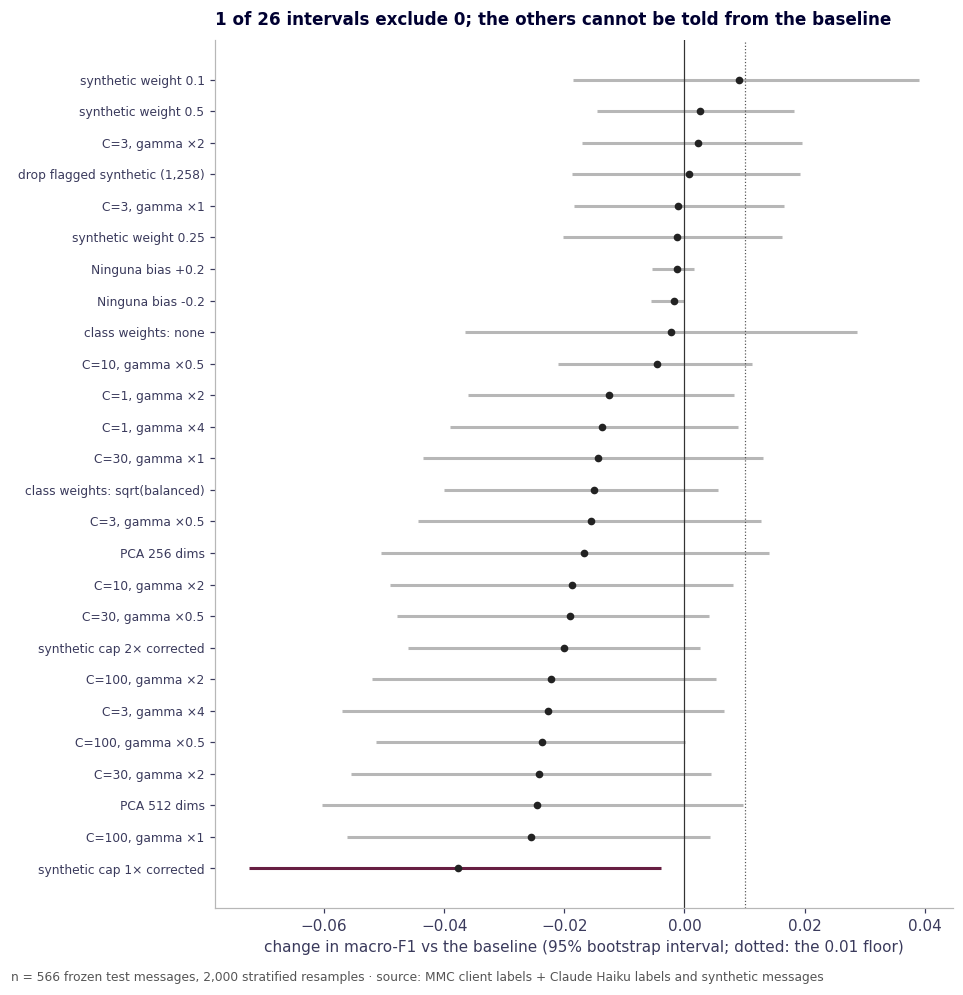

In [14]:
# --- Figure 3: paired bootstrap, change in macro-F1 against the baseline with its 95% interval ---
d = bt.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.8, 0.28 * len(d) + 1.6))
sig = (d["lo"] > 0) | (d["hi"] < 0)
ax.hlines(range(len(d)), d["lo"], d["hi"], color=[theme.WINE if s else theme.GREY for s in sig], lw=2)
ax.plot(d["Δ macro-F1"], range(len(d)), "o", color="#222", ms=4)
ax.axvline(0, color="#333", lw=0.8); ax.axvline(0.01, color="#555", lw=0.8, ls=":")
ax.set_yticks(range(len(d)), d["Variant"], fontsize=8); ax.set_xlabel("change in macro-F1 vs the baseline (95% bootstrap interval; dotted: the 0.01 floor)")
ax.set_title(f"{int(sig.sum())} of {len(d)} intervals exclude 0; the others cannot be told from the baseline", loc="left", fontsize=11)
fig.text(0.01, -0.01, f"n = {int(has_final.sum())} frozen test messages, {B:,} stratified resamples · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 8 · What this does and does not show

Computed from the cells above, so the sentences cannot drift from the numbers.

In [15]:
fin_row = res_all = pd.DataFrame(RESULTS).set_index("Variant").loc[FINAL_NAME]
allr = pd.DataFrame(RESULTS)
print(f"Fits: {len(allr)} · total fit time {allr['Fit (s)'].sum() / 60:.0f} min.")
print(f"Baseline (notebook 5's choice): accuracy {base['Acc (final labels)']:.1%}, macro-F1 {base['Final labels']:.3f}.")
print(f"Grid: macro-F1 from {f1g.to_numpy().min():.3f} to {f1g.to_numpy().max():.3f}; {int((f1g.to_numpy() >= BASE_F1 - 0.005).sum())} of {f1g.size} cells are within 0.005 of the baseline.")
print(f"Step 2: {int((show['Δ macro-F1 vs centre'] >= 0.01).sum())} of {len(show)} variants reach +0.01; best {show.loc[show['Δ macro-F1 vs centre'].idxmax(), 'Variant']} ({show['Δ macro-F1 vs centre'].max():+.3f}), worst {show.loc[show['Δ macro-F1 vs centre'].idxmin(), 'Variant']} ({show['Δ macro-F1 vs centre'].min():+.3f}).")
print(f"Final setting: {FINAL_NAME} — accuracy {fin_row['Acc (final labels)']:.1%}, macro-F1 {fin_row['Final labels']:.3f} ({fin_row['Final labels'] - base['Final labels']:+.3f}); {FINAL_NOTE}.")
print(f"Edge of the grid: best new cell C={best_new[0]}, gamma ×{best_new[1]:g} at {cells_e[best_new]:.3f} ({cells_e[best_new] - BASE_F1:+.3f}); " + ("adopted." if EDGE_ADOPTED else "not adopted."))
print(f"Bootstrap: typical half-width of a paired macro-F1 difference {((bt['hi'] - bt['lo']) / 2).median():.3f}; "
      f"{int(((bt['lo'] > 0) | (bt['hi'] < 0)).sum())} of {len(bt)} variants differ from the baseline beyond chance.")
w5 = bt[bt["Variant"] == "synthetic weight 0.5"].iloc[0]
print(f"Synthetic weight 0.5: {w5['Δ macro-F1']:+.3f} macro-F1 (95% {w5['lo']:+.3f} to {w5['hi']:+.3f}), accuracy {w5['Δ acc']:+.1%} ({w5['acc lo']:+.1%} to {w5['acc hi']:+.1%}); better in {w5['P(better)']:.0%} of resamples.")
print("Per-class change of the final setting: largest gain " + f"{pc['Δ'].idxmax()} ({pc['Δ'].max():+.2f}), largest loss {pc['Δ'].idxmin()} ({pc['Δ'].min():+.2f}).")

Fits: 27 · total fit time 48 min.
Baseline (notebook 5's choice): accuracy 83.2%, macro-F1 0.769.
Grid: macro-F1 from 0.745 to 0.772; 4 of 12 cells are within 0.005 of the baseline.
Step 2: 0 of 12 variants reach +0.01; best synthetic weight 0.1 (+0.010), worst synthetic cap 1× corrected (-0.038).
Final setting: C=10, gamma ×1  (baseline) — accuracy 83.2%, macro-F1 0.769 (+0.000); no group passed the rule.
Edge of the grid: best new cell C=1, gamma ×2 at 0.756 (-0.013); not adopted.
Bootstrap: typical half-width of a paired macro-F1 difference 0.026; 1 of 26 variants differ from the baseline beyond chance.
Synthetic weight 0.5: +0.003 macro-F1 (95% -0.015 to +0.018), accuracy +0.5% (-0.4% to +1.4%); better in 63% of resamples.
Per-class change of the final setting: largest gain Asist. Humanitaria (+0.00), largest loss Asist. Humanitaria (+0.00).


**Reading.** (macro-F1 against the final labels; the baseline is notebook 5's choice, 0.769 and 83.2%)

- **The baseline reproduces notebook 5** (asserted), so all 27 fits start from the same point.
- **C × gamma shows no better setting, and the edge does not hide one.** The 12-cell grid spans 0.745 to 0.772 with no direction. The best cell (C=3, gamma ×2, 0.772) is +0.003 above the baseline. The three extra fits beyond it (§6) are lower: C=1 gives 0.756 at gamma ×2 and ×4, and C=3 at gamma ×4 gives 0.747. So the best region is interior, around C=3 to 10 and gamma ×1 to ×2, and it is flat. Larger C (30, 100) is slightly worse.
- **None of the 12 one-change variants passes the rule.** The closest, synthetic weight 0.1, is +0.010 (0.779), but the weights have no trend (0.5: +0.003, 0.25: -0.001, 0.1: +0.010) and its neighbour 0.25 is below the baseline. Synthetic weight 0.5 is +0.003 macro-F1 and +0.5 points of accuracy; it beats the baseline in 63% of resamples (§7), so it is not distinguishable from it.
- **The test is too small to separate most of these settings.** The baseline's macro-F1 is 0.768 with a 95% bootstrap interval of 0.717 to 0.815 (accuracy 83.2%, 80.2% to 86.0%). The typical half-width of a *paired* difference to the baseline is 0.026 macro-F1. Only 1 of the 26 variants differs from the baseline beyond chance: capping the synthetic messages at 1× the Corrected count, which is lower (-0.038, interval -0.073 to -0.004). Every other interval contains 0.
- **The 0.01 adoption floor was lenient.** It is well below the 0.026 noise level, so passing it would not have proven a gain; the rule was the weaker of the two safeguards, and nothing passed even that. A variant would need roughly +0.03 on this test to be told from the baseline.
- **What does matter, only downwards.** Capping synthetic data hurts (1×: -0.038; 2×: -0.020, interval just touching 0), so with this RBF model the large synthetic volume helps a little, unlike LinearSVC in notebook 5. PCA to 256 or 512 dimensions hurts (-0.017, -0.025). Square-root class weights cost -0.015. Class weights off, a Ninguna bias of ±0.2 and dropping the 1,258 flagged synthetic rows change nothing (all within ±0.002), so keeping all synthetic rows is harmless.
- **Conclusion.** Notebook 5's setting (RBF SVM, C=10, default gamma, balanced class weights, synthetic at full weight, all 26,057 messages) stays. It sits on a plateau, and with 566 scored test messages, no tried change could be shown to beat it. Because the variants were compared on the test itself, any small gain above would also be optimistic.

**Limits to keep in mind.**

- The variants are compared on the same 588-message test as notebook 5 (566 with a final label), so the best variant's
  score is optimistic by construction (selected on the test). The 0.01 floor and the neighbour check are there to
  stop a lucky cell from being adopted; they do not remove the effect.
- One test message moves accuracy by about 0.2 points and a small class's F1 by 0.05–0.1; differences of a point or
  two between variants are inside that noise.
- The final labels are Haiku's, from the same model family that wrote the synthetic messages, so this view favours
  training on them. The numbers are agreement with Haiku's convention, not independent evidence.
- Only one-parameter changes around one centre were tried (plus one combination step), so a better setting that needs
  several simultaneous changes would not be found.